# DS5110 Homework 2: tidy, reshape, join

Three files from three systems → one tidy, analysis-ready table.
Every step below runs in order, top to bottom. The reasoning behind each decision is in `WRITEUP.md`.

| File | What it holds |
| --- | --- |
| `data/company_quarterly_revenue_raw.csv` | revenue per company per quarter |
| `data/orders.csv` | one line per customer order |
| `data/shipments.csv` | tracking numbers for shipped packages |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("data")
FIGURES = Path("figures")
OUTPUT = Path("output")
FIGURES.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)

# one fixed colour per company, used in every chart
colors = {"Acme": "#4c72b0", "Globex": "#dd8452", "Initech": "#55a868",
          "Soylent": "#c44e52", "Umbrella": "#8172b3"}

## Step 0: Descriptive analysis (before changing anything)

Load each file exactly as it comes, report its shape, and look at the first rows.

In [2]:
revenue_raw = pd.read_csv(DATA / "company_quarterly_revenue_raw.csv")
orders = pd.read_csv(DATA / "orders.csv")
shipments = pd.read_csv(DATA / "shipments.csv")

print("revenue_raw shape:", revenue_raw.shape)
print("orders shape:     ", orders.shape)
print("shipments shape:  ", shipments.shape)

revenue_raw shape: (5, 13)
orders shape:      (20, 5)
shipments shape:   (35, 2)


In [3]:
revenue_raw.head()

,company,2023-Q1,2023-Q2,2023-Q3,2023-Q4,2024-Q1,2024-Q2,2024-Q3,2024-Q4,2025-Q1,2025-Q2,2025-Q3,2025-Q4
0,Acme,13.5,14.1,15.9,16.8,15.6,16.7,18.4,17.1,18.6,19.9,20.5,20.3
1,Globex,10.3,8.7,9.4,10.7,13.5,12.0,11.6,11.6,14.0,13.8,15.9,14.0
2,Initech,16.9,15.7,16.7,16.8,17.1,17.9,18.1,18.4,18.6,17.9,20.2,22.3
3,Soylent,10.8,12.9,14.9,15.4,15.5,19.4,20.1,22.1,23.0,22.9,22.0,23.6
4,Umbrella,8.1,6.1,7.7,8.7,9.6,8.7,11.7,10.4,9.8,11.8,12.4,14.3


In [4]:
orders.head()

,order_id,customer_id,amount,company,quarter
0,O1000,C106,26,Umbrella,2024-Q4
1,O1001,C105,48,Umbrella,2023-Q3
2,O1002,C103,155,Globex,2025-Q2
3,O1003,C100,38,Acme,2023-Q4
4,O1004,C103,136,Globex,2023-Q3


In [5]:
shipments.head(8)

,order_id,tracking
0,O1000,O1000-1
1,O1001,O1001-1
2,O1001,O1001-2
3,O1002,O1002-1
4,O1003,O1003-1
5,O1003,O1003-2
6,O1004,O1004-1
7,O1004,O1004-2


To judge tidiness we first need to know **what one row represents** in each file.

In [6]:
print("revenue_raw: one row per company?    ", not revenue_raw["company"].duplicated().any())
print("orders:      one row per order?      ", not orders["order_id"].duplicated().any())
print("shipments:   one row per tracking #? ", not shipments["tracking"].duplicated().any())

revenue_raw: one row per company?     True
orders:      one row per order?       True
shipments:   one row per tracking #?  True


### Is each file tidy?

The three rules (Wickham): **(1)** every variable is a column, **(2)** every observation is a row, **(3)** every value is a cell.

**`company_quarterly_revenue_raw.csv` (5 × 13): not tidy.**
- Rule 1 fails. *Quarter* is a variable, but its values (`2023-Q1` … `2025-Q4`) are stored as 12 column **names** instead of in one `quarter` column. *Revenue*, also one variable, is spread across those 12 columns.
- Rule 2 fails. One observation is "one company's revenue in one quarter". Each row packs 12 of them.
- Rule 3 holds. Every cell holds a single number.

**`orders.csv` (20 × 5): tidy.**
- Rule 1: each column is one variable (`order_id`, `customer_id`, `amount`, `company`, `quarter`).
- Rule 2: each row is one order (`order_id` has no duplicates, checked above).
- Rule 3: one value per cell. (`quarter` like `2023-Q1` is one variable, the period, written the same way as the revenue headers. That is what lets us join the two later.)

**`shipments.csv` (35 × 2): tidy, for its own unit.**
- Rule 2: each row is one **shipment** (one package; `tracking` has no duplicates), not one order. `order_id` repeats, so this table is at a finer level than `orders`.
- Rules 1 and 3: two variables, one value per cell. `tracking` repeats the order id inside it (`O1001-2`), but it is an ID label, a single value.

### Exploratory charts of the raw data

One chart per file, each plotted from the file in the shape it arrived.

**Revenue, straight from the wide table.** Each company is a row, so we loop over the rows and use the column names as the x-axis.
This is wrapped in a function so Step 5 can redraw it next to the final chart.

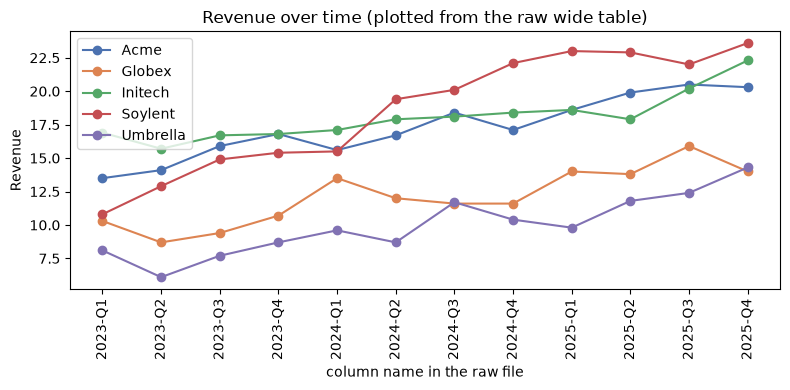

In [7]:
def plot_raw_revenue(ax):
    wide = revenue_raw.set_index("company")
    for c in wide.index:
        ax.plot(wide.columns, wide.loc[c], marker="o", color=colors[c], label=c)
    ax.set_title("Revenue over time (plotted from the raw wide table)")
    ax.set_xlabel("column name in the raw file")
    ax.set_ylabel("Revenue")
    ax.tick_params(axis="x", labelrotation=90)
    ax.legend()


fig, ax = plt.subplots(figsize=(8, 4))
plot_raw_revenue(ax)
plt.tight_layout()
fig.savefig(FIGURES / "step0_revenue_raw.png", dpi=150)
plt.show()

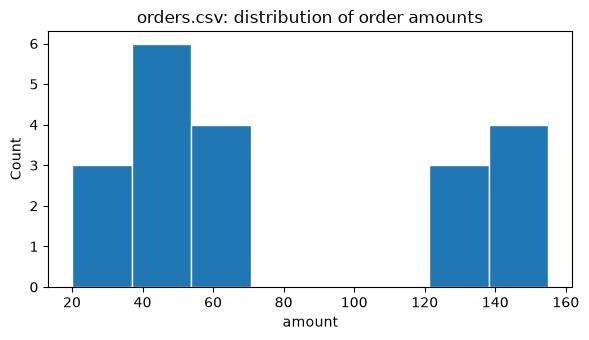

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(orders["amount"], bins=8, edgecolor="white")
ax.set_title("orders.csv: distribution of order amounts")
ax.set_xlabel("amount")
ax.set_ylabel("Count")
plt.tight_layout()
fig.savefig(FIGURES / "step0_orders_raw.png", dpi=150)
plt.show()

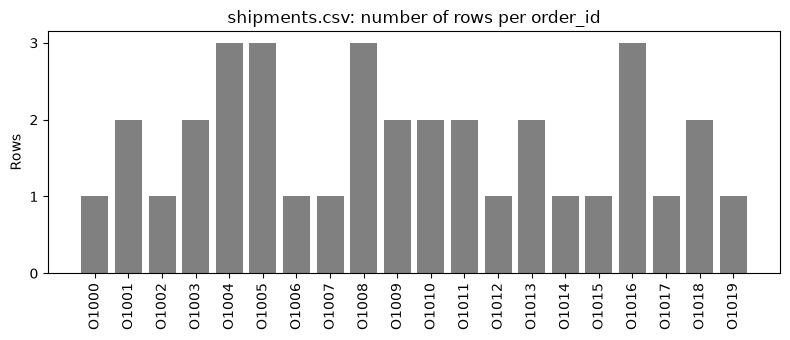

In [9]:
rows_per_order = shipments["order_id"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(rows_per_order.index, rows_per_order.values, color="gray")
ax.set_title("shipments.csv: number of rows per order_id")
ax.set_ylabel("Rows")
ax.set_yticks([0, 1, 2, 3])
ax.tick_params(axis="x", labelrotation=90)
plt.tight_layout()
fig.savefig(FIGURES / "step0_shipments_raw.png", dpi=150)
plt.show()

What the raw charts already show:
- **Revenue:** every company grows over time. But the chart only works because we looped over rows and matched columns by hand; a sixth company or a new quarter means the table changes shape.
- **Orders:** most orders are under 70, with a second group around 120–155.
- **Shipments:** many `order_id`s have 2 or 3 rows. This is the first hint that `order_id` is **not** a unique key in `shipments`.

## Step 1: Revenue table, wide → long

The revenue table is **wide**: one row per company, one column per quarter.
`melt` moves the 12 quarter column names down into a single `quarter` column, so each row becomes one (company, quarter) observation.

In [10]:
revenue = revenue_raw.melt(id_vars="company", var_name="quarter", value_name="revenue")
revenue = revenue.sort_values(["company", "quarter"]).reset_index(drop=True)

n_companies = revenue_raw.shape[0]
n_quarters = revenue_raw.shape[1] - 1  # every column except "company"
print("expected rows:", n_companies, "x", n_quarters, "=", n_companies * n_quarters)
print("actual shape: ", revenue.shape)

assert len(revenue) == n_companies * n_quarters
assert not revenue.duplicated(subset=["company", "quarter"]).any()  # one row per (company, quarter)
revenue.head(6)

expected rows: 5 x 12 = 60
actual shape:  (60, 3)


,company,quarter,revenue
0,Acme,2023-Q1,13.5
1,Acme,2023-Q2,14.1
2,Acme,2023-Q3,15.9
3,Acme,2023-Q4,16.8
4,Acme,2024-Q1,15.6
5,Acme,2024-Q2,16.7


Same 60 numbers, new layout: `company` and `quarter` identify each row, `revenue` is the measured value. All three rules now hold.

## Step 2: Is `order_id` really a unique key?

Check before joining, never after: `df.duplicated(subset=key_cols).any()`. If that is `True`, it is not the key we think it is.

In [11]:
print("orders:    order_id unique?", not orders.duplicated(subset=["order_id"]).any())
print("shipments: order_id unique?", not shipments.duplicated(subset=["order_id"]).any())
print()
print("orders:    ", len(orders), "rows,", orders["order_id"].nunique(), "different order_ids")
print("shipments: ", len(shipments), "rows,", shipments["order_id"].nunique(), "different order_ids")

orders:    order_id unique? True
shipments: order_id unique? False

orders:     20 rows, 20 different order_ids
shipments:  35 rows, 20 different order_ids


In [12]:
# How many orders have 1, 2 or 3 shipment rows?
# left: rows in shipments for one order, right: how many orders have that many
rows_per_order.value_counts().sort_index()

count
1    9
2    7
3    4
Name: count, dtype: int64

In [13]:
# Do the keys match up? An order with no shipment (or the reverse) would change the row count too.
print("shipments with no matching order:", set(shipments["order_id"]) - set(orders["order_id"]))
print("orders with no shipment:         ", set(orders["order_id"]) - set(shipments["order_id"]))

shipments with no matching order: set()
orders with no shipment:          set()


**What this means for the join:** `order_id` is unique in `orders` but repeats in `shipments`, so the join is **one-to-many (1:many)**.
Each order row will be copied once per matching shipment.

**Prediction:** rows after the join = for each order, 1 (its row in `orders`) × its number of rows in `shipments`, added up.
Every order has at least one shipment, so that is exactly the number of rows in `shipments`.

In [14]:
predicted_rows = (1 * rows_per_order).sum()
print("predicted rows after joining orders to shipments:", predicted_rows)

predicted rows after joining orders to shipments: 35


## Step 3: Join orders and shipments, then mean amount per customer

A left join keeps every order even if it had no shipment (there are none here, but the code should never silently drop an order).
Print the row count before and after, and check it against the prediction.

In [15]:
print("orders rows:   ", len(orders))
print("shipments rows:", len(shipments))

joined = orders.merge(shipments, on="order_id", how="left")
print("joined rows:   ", len(joined), "(predicted", predicted_rows, ")")

assert len(joined) == predicted_rows
joined.head(6)

orders rows:    20
shipments rows: 35
joined rows:    35 (predicted 35 )


,order_id,customer_id,amount,company,quarter,tracking
0,O1000,C106,26,Umbrella,2024-Q4,O1000-1
1,O1001,C105,48,Umbrella,2023-Q3,O1001-1
2,O1001,C105,48,Umbrella,2023-Q3,O1001-2
3,O1002,C103,155,Globex,2025-Q2,O1002-1
4,O1003,C100,38,Acme,2023-Q4,O1003-1
5,O1003,C100,38,Acme,2023-Q4,O1003-2


Notice order `O1001` now appears twice with `amount = 48` both times. The amount was **copied**, not doubled in reality.

In [16]:
naive_mean = joined.groupby("customer_id")["amount"].mean().round(2)     # (a) on the joined table
correct_mean = orders.groupby("customer_id")["amount"].mean().round(2)   # (b) on orders alone

compare = pd.DataFrame({
    "orders": orders["customer_id"].value_counts(),
    "rows_in_joined": joined["customer_id"].value_counts(),
    "naive_mean_on_joined_table": naive_mean,
    "correct_mean_on_orders_table": correct_mean,
})
compare["difference"] = (compare["naive_mean_on_joined_table"]
                         - compare["correct_mean_on_orders_table"]).round(2)
compare.sort_index()

,orders,rows_in_joined,naive_mean_on_joined_table,correct_mean_on_orders_table,difference
customer_id,,,,,
C100,1,2,38.00,38.00,0.00
C101,1,1,62.00,62.00,0.00
C102,2,2,105.00,105.00,0.00
C103,5,8,112.38,111.60,0.78
C104,1,1,33.00,33.00,0.00
C105,4,8,67.62,67.25,0.37
C106,4,8,62.25,59.50,2.75
C107,2,5,106.00,96.50,9.50


In [17]:
# Worked example: customer C107, the largest gap
joined[joined["customer_id"] == "C107"][["order_id", "amount", "tracking"]]

,order_id,amount,tracking
9,O1005,144,O1005-1
10,O1005,144,O1005-2
11,O1005,144,O1005-3
19,O1010,49,O1010-1
20,O1010,49,O1010-2


**Which one is correct? (b), the mean on `orders` alone.**

`amount` belongs to the **order**, not to the shipment. The join copies each order's amount once per shipment, so an order shipped in 3 boxes is counted 3 times in the average.
C107 placed two orders: 144 (3 shipments) and 49 (2 shipments).
- (a) joined: (144 + 144 + 144 + 49 + 49) / 5 = **106.0**, pulled toward the order that shipped in more boxes
- (b) orders: (144 + 49) / 2 = **96.5**, each order counted once

The numbers only agree for customers whose orders each shipped once (`difference == 0`), which is why the bug is easy to miss.

### Joining correctly

The fix: **aggregate `shipments` to one row per order before joining** (a count of shipments per order). Now `order_id` is unique on both sides, the join is one-to-one, and the order count cannot change.

In [18]:
shipment_counts = shipments.groupby("order_id").agg(
    n_shipments=("tracking", "count"),
).reset_index()

assert not shipment_counts.duplicated(subset=["order_id"]).any()  # now one row per order

orders_clean = orders.merge(shipment_counts, on="order_id", how="left")

print("orders rows:      ", len(orders))
print("orders_clean rows:", len(orders_clean))
assert len(orders_clean) == len(orders)                       # 1:1 -> row count unchanged
assert orders_clean["n_shipments"].notna().all()              # every order found its count
assert orders_clean["n_shipments"].sum() == len(shipments)    # no shipment lost
assert orders_clean.groupby("customer_id")["amount"].mean().round(2).equals(correct_mean)  # matches (b)
orders_clean.head()

orders rows:       20
orders_clean rows: 20


,order_id,customer_id,amount,company,quarter,n_shipments
0,O1000,C106,26,Umbrella,2024-Q4,1
1,O1001,C105,48,Umbrella,2023-Q3,2
2,O1002,C103,155,Globex,2025-Q2,1
3,O1003,C100,38,Acme,2023-Q4,2
4,O1004,C103,136,Globex,2023-Q3,3


## Step 4: One analysis-ready table

Unit of observation: **one order**. Each order gets the revenue of its company in the quarter it was placed.

Key check first: in `revenue`, (company, quarter) is unique (asserted in Step 1). In `orders_clean` it repeats, because a company can have several orders in one quarter. So this join is **many-to-one**, and the row count should stay at 20.

In [19]:
key = ["company", "quarter"]
print("revenue:      (company, quarter) unique?", not revenue.duplicated(subset=key).any())
print("orders_clean: (company, quarter) unique?", not orders_clean.duplicated(subset=key).any())

final = orders_clean.merge(revenue, on=key, how="left")

print("orders_clean rows:", len(orders_clean))
print("final rows:       ", len(final))
assert len(final) == len(orders_clean)        # many:1 -> row count unchanged
assert final["revenue"].notna().all()         # every order found its (company, quarter) revenue

revenue:      (company, quarter) unique? True
orders_clean: (company, quarter) unique? False
orders_clean rows: 20
final rows:        20


In [20]:
final = final.rename(columns={"amount": "order_amount", "revenue": "company_quarter_revenue"})
final = final[["order_id", "customer_id", "company", "quarter",
               "order_amount", "n_shipments", "company_quarter_revenue"]]
final = final.sort_values("order_id").reset_index(drop=True)

# Tidy checks
assert not final.duplicated(subset=["order_id"]).any()   # one row per order
assert final.notna().all().all()                         # no gaps
assert "Unnamed: 0" not in final.columns                 # no leftover index column

final.to_csv(OUTPUT / "orders_analysis_ready.csv", index=False)
print(final.shape)
final

(20, 7)


,order_id,customer_id,company,quarter,order_amount,n_shipments,company_quarter_revenue
0,O1000,C106,Umbrella,2024-Q4,26,1,10.4
1,O1001,C105,Umbrella,2023-Q3,48,2,7.7
2,O1002,C103,Globex,2025-Q2,155,1,13.8
3,O1003,C100,Acme,2023-Q4,38,2,16.8
4,O1004,C103,Globex,2023-Q3,136,3,9.4
5,O1005,C107,Soylent,2023-Q4,144,3,15.4
6,O1006,C101,Acme,2024-Q3,62,1,18.4
7,O1007,C103,Globex,2025-Q2,64,1,13.8
8,O1008,C106,Umbrella,2025-Q2,48,3,11.8
9,O1009,C105,Umbrella,2023-Q2,122,2,6.1


In [21]:
final.dtypes

order_id                       str
customer_id                    str
company                        str
quarter                        str
order_amount                 int64
n_shipments                  int64
company_quarter_revenue    float64
dtype: object

**Column guide**

| Column | Meaning | Source |
| --- | --- | --- |
| `order_id` | order identifier (unique) | orders |
| `customer_id` | who placed the order | orders |
| `company` | company the order was placed with | orders |
| `quarter` | quarter the order was placed, `YYYY-Qn` | orders |
| `order_amount` | value of the order | orders |
| `n_shipments` | number of packages the order shipped in | shipments, counted per order |
| `company_quarter_revenue` | that company's total revenue in that quarter (units not given in the source) | revenue, melted |

**Caution for whoever uses this table:** `company_quarter_revenue` repeats when a company has several orders in the same quarter. Never sum it down this table; use the long `revenue` table for revenue totals.

## Step 5: A chart from the final table, next to the raw chart

The new chart puts three sources on one plot: revenue on x (needed the melt), order amount on y (orders), and dot size = number of shipments (needed counting shipments per order).

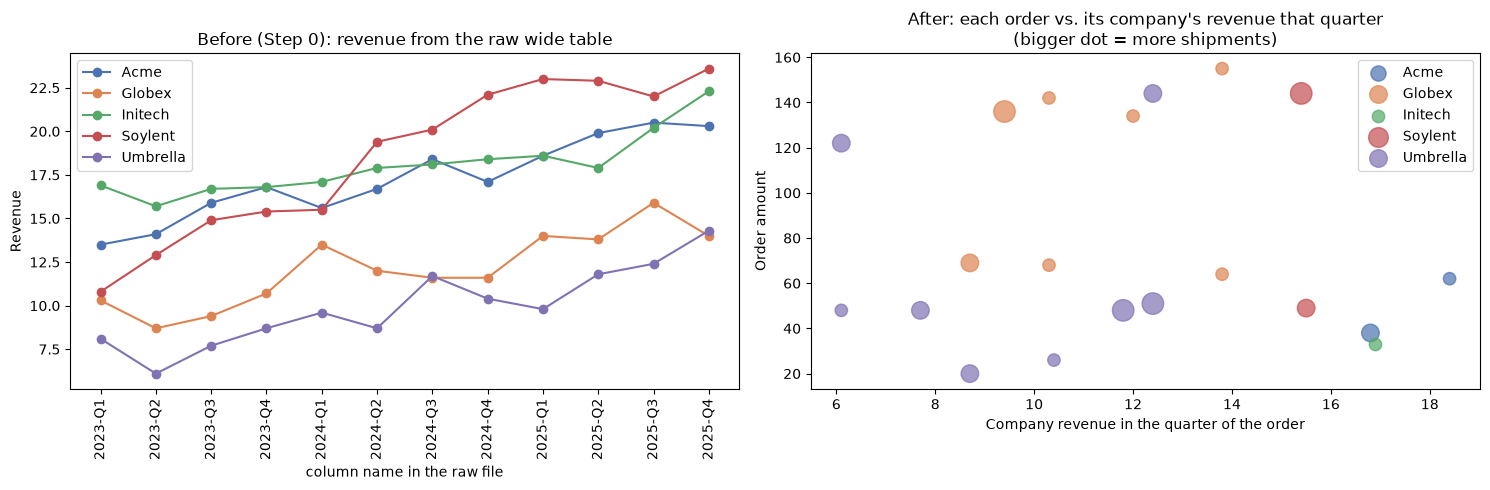

In [22]:
fig, (ax_raw, ax_new) = plt.subplots(1, 2, figsize=(15, 5))

# Before: the Step 0 chart, from the raw wide table
plot_raw_revenue(ax_raw)
ax_raw.set_title("Before (Step 0): revenue from the raw wide table")

# After: one groupby loop over the final table
for company, g in final.groupby("company"):
    ax_new.scatter(g["company_quarter_revenue"], g["order_amount"],
                   s=g["n_shipments"] * 80, color=colors[company], alpha=0.7, label=company)

ax_new.set_title("After: each order vs. its company's revenue that quarter\n(bigger dot = more shipments)")
ax_new.set_xlabel("Company revenue in the quarter of the order")
ax_new.set_ylabel("Order amount")
ax_new.legend()

plt.tight_layout()
fig.savefig(FIGURES / "step5_before_after.png", dpi=150)
plt.show()

**What got easier:** in the raw files, the revenue for an order's quarter was hidden in a column *name* of one file, and the number of shipments was spread across several rows of another file. Putting both next to an order would have meant looking up a column by name for every order and counting rows by hand.
After tidying and joining, every visual channel (x, y, colour, size) is just one column of one table, the same `groupby` loop from class draws it, and no order is counted more than once. A new company or quarter needs zero changes to the plotting code.